<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 1, Experimentando Depth Estimation y Object Detection**

Importamos lo necesario

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import pipeline
from PIL import Image
from google.colab import files

Cargamos detector y estimador de profundidad

In [ ]:
detector = pipeline("zero-shot-object-detection", model="google/owlvit-base-patch32")
profundidad = pipeline("depth-estimation", model="Intel/zoedepth-nyu-kitti")

Loading weights:   0%|          | 0/412 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/647 [00:00<?, ?it/s]

Cargar una foto de una calle, un aula o una habitación

In [ ]:
subidos = files.upload()
imagen = Image.open(list(subidos.keys())[0]).convert("RGB")

Saving images (30).jpeg to images (30) (2).jpeg


In [ ]:
objetos = detector(imagen, candidate_labels=["person", "car"])

Profundidad en metros para cada píxel

In [ ]:
Z = torch.as_tensor(profundidad(imagen)["predicted_depth"]).squeeze()
if Z.shape != (imagen.height, imagen.width):
    Z = torch.nn.functional.interpolate(Z[None, None], size=(imagen.height, imagen.width), mode="bilinear")[0, 0]
Z = Z.numpy()

Distancia de cada objeto: la mediana de la profundidad dentro de su caja

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


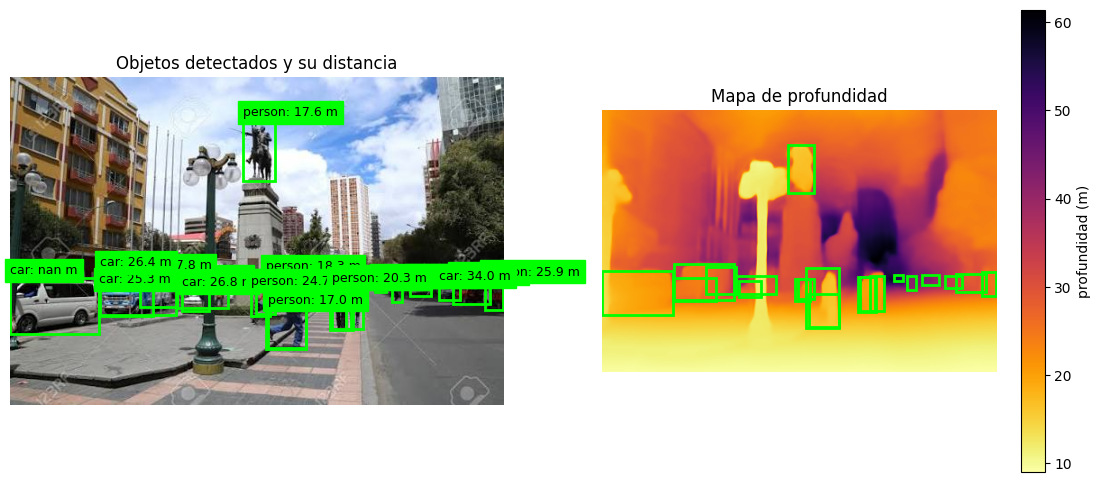

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
axs[0].imshow(imagen)
im = axs[1].imshow(Z, cmap="inferno_r")       # oscuro = lejos, claro = cerca
plt.colorbar(im, ax=axs[1], label="profundidad (m)")

for o in objetos:
    b = o["box"]
    d = np.median(Z[b["ymin"]:b["ymax"], b["xmin"]:b["xmax"]])
    for ax in axs:
        ax.add_patch(plt.Rectangle((b["xmin"], b["ymin"]), b["xmax"] - b["xmin"], b["ymax"] - b["ymin"],
                                   fill=False, color="lime", linewidth=2))
    axs[0].text(b["xmin"], b["ymin"] - 5, f'{o["label"]}: {d:.1f} m', color="black", backgroundcolor="lime", fontsize=9)

axs[0].set_title("Objetos detectados y su distancia")
axs[1].set_title("Mapa de profundidad")
for ax in axs:
    ax.axis("off")
plt.show()

**Ejercicios**
* quién está más cerca? pasar una foto con dos o tres personas a distintas distancias
* cambiar los objetos,cambiar candidate_labels por objetos del aula, por ejemplo ["laptop", "backpack", "bottle"], los detecta todos? la distancia que da tiene sentido?